# E-commerce Sales Analysis

Exploratory analysis of the e-commerce sales data in `ecommerce_data/`. The analysis period and the comparison period are set in the configuration cell. With the default configuration it covers January to December 2023, compared with January to December 2022.

## Table of Contents

1. [Introduction & Business Objectives](#introduction)
2. [Data Loading & Configuration](#configuration)
3. [Data Dictionary](#data-dictionary)
4. [Data Preparation & Transformation](#data-preparation)
5. [Business Metrics Calculation](#business-metrics)
    - 5.1 [Revenue Analysis](#revenue)
    - 5.2 [Product Category Analysis](#product)
    - 5.3 [Geographic Analysis](#geographic)
    - 5.4 [Customer Experience Analysis](#customer-experience)
6. [Summary of Observations](#summary)

<a id="introduction"></a>
## 1. Introduction & Business Objectives

This notebook answers the following questions for a configurable period, compared with an earlier period of the same length:

- **Revenue:** How much revenue did we generate, and how does it compare with the comparison period? What is the month-over-month trend? How did average order value and order count change?
- **Product:** Which product categories generate the most revenue?
- **Geography:** How is revenue distributed across US states?
- **Customer experience:** How do customers rate their orders? How long does delivery take, and does review score vary with delivery time? What share of orders ends in each status?

### How this notebook is organised

All loading and cleaning logic lives in `data_loader.py`, all metric calculations in `business_metrics.py`, and all charts in `visualizations.py`. The notebook sets the configuration, calls these modules and documents the results. To analyse a different period, edit the configuration cell in Section 2 and re-run all cells.

### Relationship to the original `EDA.ipynb`

This notebook reproduces every metric and chart from `EDA.ipynb` and fixes the following issues:

- Hardcoded 2022/2023 filters are replaced with a configurable month range that can span years.
- The `SettingWithCopyWarning` caused by assigning columns on a filtered slice is gone, because filtering returns explicit copies.
- Row-wise `.apply(lambda)` calls for date parts are replaced with vectorised `.dt` accessors.
- The source `orders` table is no longer modified in place.
- Merges use explicit `on` and `how` arguments.
- Plots have titles that include the period, axis labels with units, and a consistent palette.

<a id="configuration"></a>
## 2. Data Loading & Configuration

### 2.1 Analysis configuration

Every setting that controls the analysis is in the cell below.

- **Analysis period:** an inclusive month range. It can be a full year, a quarter, a single month, or a range that crosses a year boundary.
- **Comparison period:** by default, the same months one year earlier. Set `COMPARE_TO_PREVIOUS_YEAR = False` and fill in the `COMPARISON_*` values to compare against any other period, or set them to `None` to skip the comparison.
- **Order status:** sales metrics use only orders with this status. The original analysis used `'delivered'`.
- **Delivery-time buckets:** used to group orders by delivery time. The values below reproduce the buckets in the original analysis (1-3, 4-7 and 8+ days). They are an analysis choice, not a business target; change them as needed.

In [1]:
import numpy as np

# Data location
DATA_PATH = 'ecommerce_data'

# Analysis period (inclusive month range)
START_YEAR, START_MONTH = 2023, 1
END_YEAR, END_MONTH = 2023, 12

# Comparison period: same months one year earlier, or set explicit bounds below
COMPARE_TO_PREVIOUS_YEAR = True
COMPARISON_START_YEAR, COMPARISON_START_MONTH = None, None
COMPARISON_END_YEAR, COMPARISON_END_MONTH = None, None

# Order status included in sales metrics
ORDER_STATUS = 'delivered'

# Delivery-time buckets: right-inclusive edges in days, one label per bucket
DELIVERY_BIN_EDGES = [0, 3, 7, np.inf]
DELIVERY_BIN_LABELS = ['1-3 days', '4-7 days', '8+ days']

### 2.2 Imports and data loading

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from data_loader import (
    load_and_process_data,
    describe_period,
    get_comparison_period,
    add_delivery_speed_category,
)
from business_metrics import BusinessMetricsCalculator, calculate_order_status_distribution
import visualizations as viz

pd.set_option('display.float_format', '{:,.2f}'.format)

loader, processed_data = load_and_process_data(DATA_PATH)

Loaded orders: 10,000 records
Loaded order_items: 16,047 records
Loaded products: 6,000 records
Loaded customers: 8,000 records
Loaded reviews: 6,571 records
Loaded payments: 14,091 records


In [3]:
# Resolve the comparison period and build labels used in titles
if COMPARE_TO_PREVIOUS_YEAR:
    comparison_period = get_comparison_period(START_YEAR, START_MONTH, END_YEAR, END_MONTH)
elif COMPARISON_START_YEAR is not None:
    comparison_period = (COMPARISON_START_YEAR, COMPARISON_START_MONTH,
                         COMPARISON_END_YEAR, COMPARISON_END_MONTH)
else:
    comparison_period = None

analysis_period = (START_YEAR, START_MONTH, END_YEAR, END_MONTH)
PERIOD_LABEL = describe_period(*analysis_period)
COMPARISON_LABEL = describe_period(*comparison_period) if comparison_period else None

print(f"Analysis period:   {PERIOD_LABEL}")
print(f"Comparison period: {COMPARISON_LABEL or 'none'}")
print(f"Order status:      {ORDER_STATUS}")

Analysis period:   Jan 2023 - Dec 2023
Comparison period: Jan 2022 - Dec 2022
Order status:      delivered


In [4]:
# Size and date coverage of the source data
summary = loader.get_data_summary()
pd.DataFrame({name: {'rows': info['rows'], 'columns': info['columns']}
              for name, info in summary.items()}).T

,rows,columns
orders,10000,11
order_items,16047,8
reviews,6571,7
products,6000,9
customers,8000,5
payments,14091,5


In [5]:
order_dates = summary['orders']['date_range']
print(f"Orders cover purchases from {order_dates['start']:%Y-%m-%d} to {order_dates['end']:%Y-%m-%d}")

Orders cover purchases from 2021-12-31 to 2024-01-01


<a id="data-dictionary"></a>
## 3. Data Dictionary

### Source tables

| Table | Grain | Key columns used |
|---|---|---|
| `orders` | One row per order | `order_id`, `customer_id`, `order_status`, `order_purchase_timestamp`, `order_delivered_customer_date` |
| `order_items` | One row per item in an order | `order_id`, `order_item_id`, `product_id`, `price`, `freight_value` |
| `products` | One row per product | `product_id`, `product_category_name` |
| `customers` | One row per customer ID | `customer_id`, `customer_state`, `customer_city` |
| `reviews` | One row per review (at most one per order) | `order_id`, `review_score` |
| `payments` | One row per payment | Loaded but not used in this analysis |

### Key columns

| Column | Description |
|---|---|
| `order_id` | Unique order identifier |
| `order_status` | Order lifecycle state: delivered, shipped, processing, pending, canceled, returned |
| `order_purchase_timestamp` | Date and time the order was placed. All period filters use this date |
| `order_delivered_customer_date` | Date and time the order reached the customer (empty if not delivered) |
| `price` | Item price in USD, excluding freight |
| `freight_value` | Shipping charge for the item in USD |
| `product_category_name` | Product category (13 categories) |
| `customer_state` | Two-letter US state code of the customer |
| `review_score` | Customer rating from 1 (lowest) to 5 (highest) |

### Derived columns

| Column | Definition |
|---|---|
| `purchase_year`, `purchase_month` | Year and month of `order_purchase_timestamp` |
| `delivery_days` | Whole days between purchase and delivery to the customer |
| `delivery_speed_category` | `delivery_days` grouped into the buckets set in the configuration |

### Business terms

| Term | Definition |
|---|---|
| Revenue | Sum of item `price` for orders with the configured status. Freight is excluded |
| Order | A unique `order_id`. An order can contain several items |
| Average order value (AOV) | Revenue divided by number of orders, i.e. the mean of per-order revenue |
| Period-over-period change | (current - comparison) / comparison x 100. Reported as n/a when the comparison value is zero |
| Month-over-month (MoM) growth | Percent change in revenue from one month to the next. The average MoM growth is the mean of these monthly rates |
| Revenue share | A segment's revenue as a percent of total revenue in the period |

<a id="data-preparation"></a>
## 4. Data Preparation & Transformation

`create_sales_dataset` builds an item-level table with one row per order item. It joins orders, product category, customer state and review score, keeps only the configured order status, filters to the requested month range, and calculates `delivery_days`. Reviews are left-joined, so orders without a review stay in the revenue figures and get an empty `review_score`.

The same steps produce the comparison dataset. The delivery-time buckets are then added to the analysis dataset.

In [6]:
current_sales = loader.create_sales_dataset(*analysis_period, status_filter=ORDER_STATUS)
current_sales = add_delivery_speed_category(current_sales, DELIVERY_BIN_EDGES, DELIVERY_BIN_LABELS)

comparison_sales = (
    loader.create_sales_dataset(*comparison_period, status_filter=ORDER_STATUS)
    if comparison_period else None
)

# All orders in the analysis period regardless of status, for the status distribution
current_orders = loader.filter_orders_by_period(*analysis_period)

print(f"{PERIOD_LABEL}: {len(current_sales):,} item rows, {current_sales['order_id'].nunique():,} orders")
if comparison_sales is not None:
    print(f"{COMPARISON_LABEL}: {len(comparison_sales):,} item rows, {comparison_sales['order_id'].nunique():,} orders")

Jan 2023 - Dec 2023: 7,448 item rows, 4,635 orders
Jan 2022 - Dec 2022: 7,641 item rows, 4,749 orders


In [7]:
current_sales.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,total_item_value,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,purchase_year,purchase_month,product_category_name,customer_state,customer_city,review_score,delivery_days,delivery_speed_category
0,ord_5fa044951857e02fd1347b47,1,prod_9b6f1793388ae983f852d189,sell_34212979d97b6d1a8409a01e,2025-07-19 21:15:46.994884,111.91,9.50,121.41,cust_2d36e4b647be13c15df550af,delivered,2023-04-24 13:05:32.579655,2023-05-01 02:05:32.579655,2023,4,grocery_gourmet_food,TN,Knoxville,5.00,6,4-7 days
1,ord_5fa044951857e02fd1347b47,2,prod_c7b5997a4d0061a9f50e874c,sell_4668fb88b81f8d834371c335,2025-07-17 10:00:54.671461,878.42,77.50,955.92,cust_2d36e4b647be13c15df550af,delivered,2023-04-24 13:05:32.579655,2023-05-01 02:05:32.579655,2023,4,electronics,TN,Knoxville,5.00,6,4-7 days
2,ord_43b53981d951f855231d09ec,1,prod_496e129d773e9587e8ddc065,sell_6cfe47a34211c0b92f0fd126,2025-07-13 21:00:53.795592,749.83,13.94,763.77,cust_e670ce607e4f6aa14935ece0,delivered,2023-12-10 05:13:58.249202,2023-12-19 09:13:58.249202,2023,12,sports_outdoors,FL,Orlando,5.00,9,8+ days
3,ord_e60b1e267fd32d93c4d0745b,1,prod_139fc7c40b163ec81342741e,sell_bcb2c47f4631ff00586f7de0,2025-07-14 01:28:11.006814,361.54,54.65,416.19,cust_deec5ec61bd39869531896b3,delivered,2023-04-11 05:42:57.214593,2023-04-22 20:42:57.214593,2023,4,home_garden,PA,Philadelphia,5.00,11,8+ days
4,ord_e60b1e267fd32d93c4d0745b,2,prod_8668b3ebccd7183bae97138a,sell_bc4ff6f9c9f971b8fc9bf8a3,2025-07-26 07:31:46.754270,25.59,2.57,28.16,cust_deec5ec61bd39869531896b3,delivered,2023-04-11 05:42:57.214593,2023-04-22 20:42:57.214593,2023,4,grocery_gourmet_food,PA,Philadelphia,5.00,11,8+ days


#### Data coverage check

Period-over-period comparisons are only meaningful when both periods are fully covered by the data. This cell counts the months that contain data in each period. If the counts differ from the number of months requested, the comparison covers different amounts of time; interpret the change figures with that in mind.

In [8]:
def months_with_data(sales):
    """Number of distinct purchase months present in a sales dataset."""
    return sales[['purchase_year', 'purchase_month']].drop_duplicates().shape[0]

requested_months = (END_YEAR - START_YEAR) * 12 + END_MONTH - START_MONTH + 1
print(f"Months requested per period:       {requested_months}")
print(f"Months with data, {PERIOD_LABEL}: {months_with_data(current_sales)}")
if comparison_sales is not None:
    print(f"Months with data, {COMPARISON_LABEL}: {months_with_data(comparison_sales)}")

Months requested per period:       12
Months with data, Jan 2023 - Dec 2023: 12
Months with data, Jan 2022 - Dec 2022: 12


<a id="business-metrics"></a>
## 5. Business Metrics Calculation

`BusinessMetricsCalculator` takes the analysis and comparison datasets, which are already filtered, and calculates every metric. It never filters by date itself, so the same calls work for any period length.

In [9]:
calculator = BusinessMetricsCalculator(current_sales, comparison_sales)
report = calculator.generate_comprehensive_report()

<a id="revenue"></a>
### 5.1 Revenue Analysis

Total revenue, order count and average order value for the analysis period, with the percent change from the comparison period.

In [10]:
viz.print_metrics_summary(report, PERIOD_LABEL, COMPARISON_LABEL)

BUSINESS METRICS SUMMARY: Jan 2023 - Dec 2023
Compared with: Jan 2022 - Dec 2022
Total revenue:          $3,360,294.74
Total orders:           4,635
Average order value:    $724.98
Revenue change:         -2.46%
Order count change:     -2.40%
AOV change:             -0.06%
Average MoM growth:     -0.39%
Average review score:   4.10 / 5
Average delivery time:  8.0 days


In [11]:
# Headline metrics side by side
revenue = report['revenue_metrics']
headline = pd.DataFrame({
    'metric': ['Revenue (USD)', 'Orders', 'Average order value (USD)', 'Items sold'],
    PERIOD_LABEL: [revenue['total_revenue'], revenue['total_orders'],
                   revenue['average_order_value'], revenue['total_items_sold']],
})
if comparison_sales is not None:
    headline[COMPARISON_LABEL] = [revenue['previous_revenue'], revenue['previous_orders'],
                                  revenue['previous_aov'], revenue['previous_items_sold']]
    headline['change (%)'] = [revenue['revenue_growth_rate'], revenue['order_growth_rate'],
                              revenue['aov_growth_rate'],
                              (revenue['total_items_sold'] / revenue['previous_items_sold'] - 1) * 100]
headline.set_index('metric')

,Jan 2023 - Dec 2023,Jan 2022 - Dec 2022,change (%)
metric,,,
Revenue (USD),"3,360,294.74","3,445,076.96",-2.46
Orders,"4,635.00","4,749.00",-2.40
Average order value (USD),724.98,725.43,-0.06
Items sold,"7,448.00","7,641.00",-2.53


#### Month-over-month trend

Revenue, orders and AOV per month. The growth columns show the percent change from the previous month; the first month has no previous month and shows NaN.

In [12]:
monthly = report['monthly_trends']
monthly

,year,month,revenue,orders,avg_order_value,revenue_growth,order_growth,aov_growth
0,2023,1,"284,855.48",384,741.81,NaN,NaN,NaN
1,2023,2,"276,758.54",384,720.73,-2.84,0.00,-2.84
2,2023,3,"285,618.77",394,724.92,3.20,2.60,0.58
3,2023,4,"253,794.62",370,685.93,-11.14,-6.09,-5.38
4,2023,5,"301,347.96",396,760.98,18.74,7.03,10.94
5,2023,6,"289,126.72",406,712.13,-4.06,2.53,-6.42
6,2023,7,"296,209.39",392,755.64,2.45,-3.45,6.11
7,2023,8,"286,645.60",375,764.39,-3.23,-4.34,1.16
8,2023,9,"303,793.15",384,791.13,5.98,2.40,3.50
9,2023,10,"259,890.15",379,685.73,-14.45,-1.30,-13.32


In [13]:
print(f"Average month-over-month revenue growth, {PERIOD_LABEL}: "
      f"{viz.format_percentage(report['average_mom_growth'], signed=True)}")

Average month-over-month revenue growth, Jan 2023 - Dec 2023: -0.39%


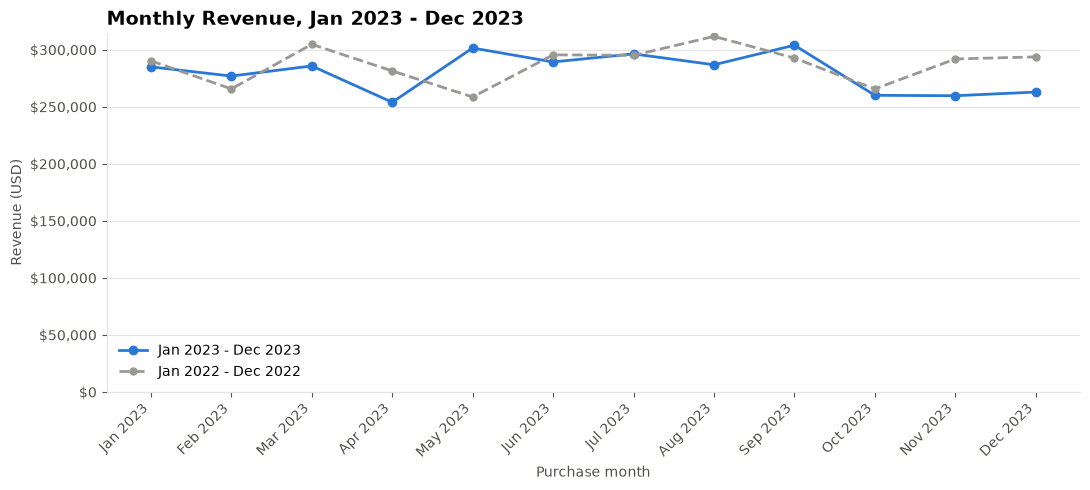

In [14]:
fig = viz.plot_monthly_revenue(monthly, PERIOD_LABEL,
                               report['comparison_monthly_trends'], COMPARISON_LABEL)
plt.show()

<a id="product"></a>
### 5.2 Product Category Analysis

Revenue by product category, with each category's share of total revenue.

In [15]:
categories = report['product_performance']
categories

,product_category_name,total_revenue,avg_item_price,items_sold,unique_orders,revenue_share
0,electronics,"1,401,359.21","1,056.04",1327,1227,41.70
1,home_garden,"862,653.27",750.79,1149,1045,25.67
2,sports_outdoors,"278,845.32",406.48,686,645,8.30
3,automotive,"247,707.10",506.56,489,473,7.37
4,clothing_shoes_jewelry,"232,745.04",263.29,884,828,6.93
5,toys_games,"70,163.64",147.40,476,461,2.09
6,health_personal_care,"65,370.27",103.76,630,613,1.95
7,tools_home_improvement,"54,280.33",247.86,219,213,1.62
8,beauty_personal_care,"49,213.30",156.23,315,309,1.46
9,books_media,"38,559.08",53.18,725,687,1.15


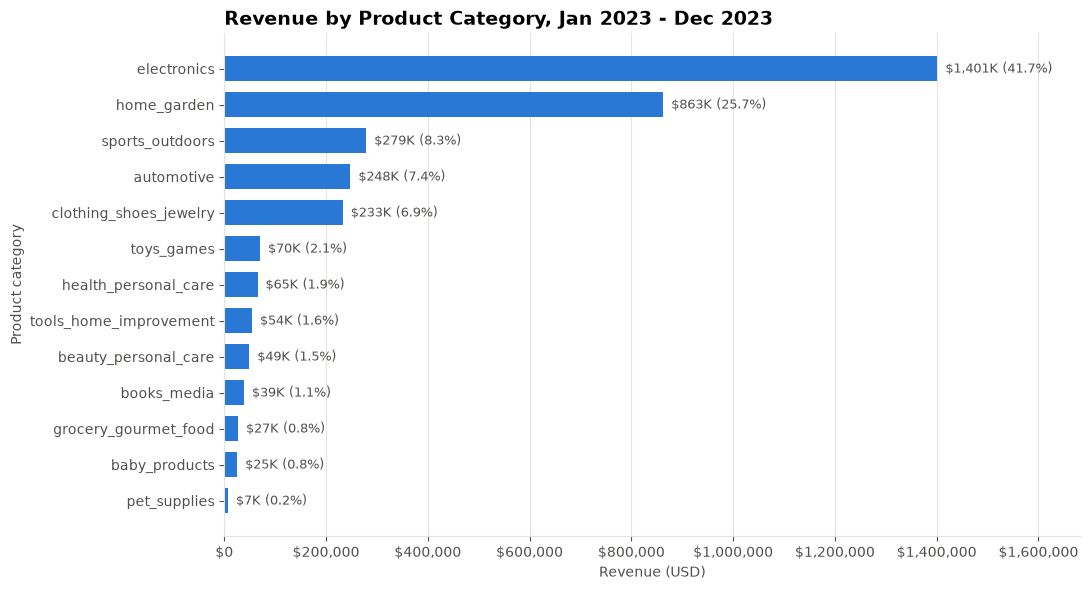

In [16]:
fig = viz.plot_category_revenue(categories, PERIOD_LABEL)
plt.show()

<a id="geographic"></a>
### 5.3 Geographic Analysis

Revenue, orders and AOV by customer state. The map is interactive: hover over a state to see its values.

In [17]:
states = report['geographic_performance']
states.head(10)

,state,revenue,orders,avg_order_value,revenue_share
0,CA,"537,880.74",769,699.45,16.01
1,TX,"403,303.49",561,718.90,12.00
2,FL,"310,195.84",431,719.71,9.23
3,NY,"253,111.85",384,659.15,7.53
4,IL,"185,930.89",260,715.12,5.53
5,PA,"173,260.68",225,770.05,5.16
6,OH,"157,619.72",200,788.10,4.69
7,GA,"146,414.65",190,770.60,4.36
8,MI,"132,325.60",210,630.12,3.94
9,NC,"128,314.74",177,724.94,3.82


In [18]:
fig = viz.plot_revenue_by_state(states, PERIOD_LABEL)
fig.show()

<a id="customer-experience"></a>
### 5.4 Customer Experience Analysis

#### Review scores

Review metrics are calculated at the order level. Orders without a review are excluded from the average and the distribution.

In [19]:
satisfaction = report['customer_satisfaction']
print(f"Average review score: {satisfaction['avg_review_score']:.2f} / 5")
print(f"Reviewed orders:      {satisfaction['total_reviews']:,} "
      f"({satisfaction['reviewed_order_share']:.1f}% of orders)")

Average review score: 4.10 / 5
Reviewed orders:      3,225 (69.6% of orders)


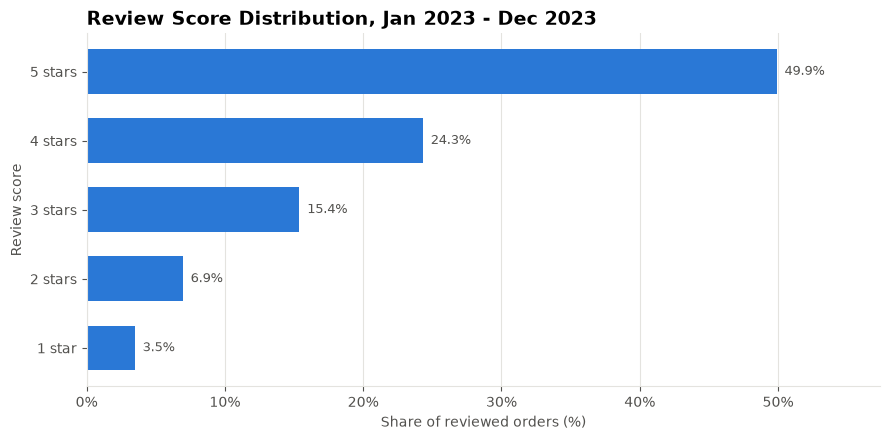

In [20]:
fig = viz.plot_review_distribution(satisfaction['score_distribution'], PERIOD_LABEL)
plt.show()

#### Delivery time

Delivery time is the number of whole days from purchase to delivery to the customer, averaged across all delivered orders in the period.

Note: the original notebook computed this average only over orders that also had a review, which gave a slightly different value (8.01 days for 2023, compared with 8.03 here).

In [21]:
delivery = report['delivery_performance']
print(f"Average delivery time: {delivery['avg_delivery_days']:.2f} days")
print(f"Median delivery time:  {delivery['median_delivery_days']:.0f} days")
print()
print('Share of orders by delivery-time bucket (%):')
print(delivery['category_distribution'].round(2).to_string())

Average delivery time: 8.03 days
Median delivery time:  8 days

Share of orders by delivery-time bucket (%):
delivery_speed_category
1-3 days    7.16
4-7 days   37.26
8+ days    55.58


#### Review score by delivery time

Average review score for each delivery time, first by individual day and then by the configured buckets. Only orders that were both delivered and reviewed are included.

In [22]:
score_by_day = calculator.review_score_by_delivery('delivery_days')
score_by_day

,delivery_days,avg_review_score,orders
0,2,4.03,59
1,3,4.25,173
2,4,4.07,250
3,5,4.05,296
4,6,4.07,340
5,7,4.10,313
6,8,3.97,347
7,9,4.12,332
8,10,4.10,327
9,11,4.15,307


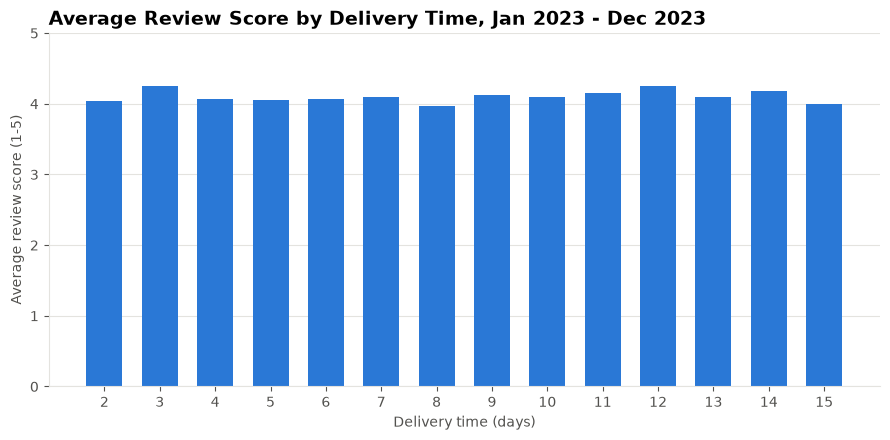

In [23]:
fig = viz.plot_review_score_by_delivery(score_by_day, 'delivery_days', PERIOD_LABEL,
                                        xlabel='Delivery time (days)')
plt.show()

In [24]:
score_by_bucket = calculator.review_score_by_delivery('delivery_speed_category')
score_by_bucket

,delivery_speed_category,avg_review_score,orders
0,1-3 days,4.19,232
1,4-7 days,4.08,1199
2,8+ days,4.11,1794


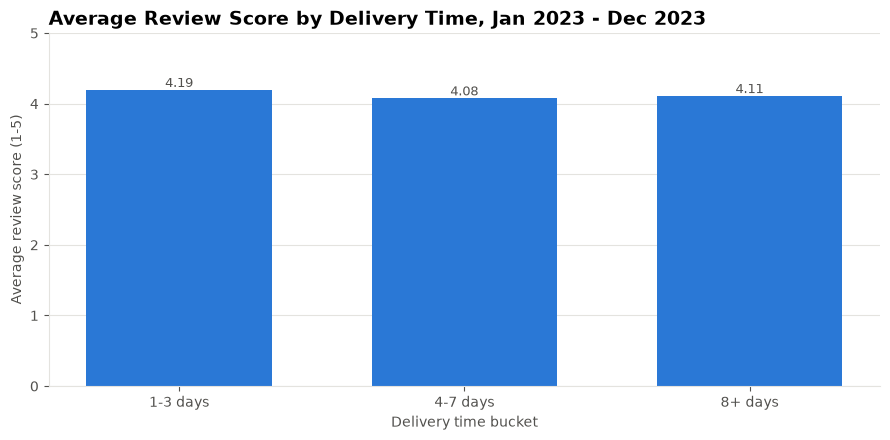

In [25]:
fig = viz.plot_review_score_by_delivery(score_by_bucket, 'delivery_speed_category', PERIOD_LABEL,
                                        xlabel='Delivery time bucket')
plt.show()

#### Order status distribution

Share of all orders placed in the period in each status. This includes orders that were not delivered.

In [26]:
status_distribution = calculate_order_status_distribution(current_orders)
status_distribution

,order_status,orders,share
0,delivered,4635,93.64
1,shipped,158,3.19
2,canceled,64,1.29
3,processing,59,1.19
4,pending,25,0.51
5,returned,9,0.18


<a id="summary"></a>
## 6. Summary of Observations

The cell below states the main results as plain facts, using the values calculated above, so it stays correct when the configuration changes. It does not label results as good or bad, because no business targets are defined for this data.

In [27]:
import calendar

def describe_change(value):
    """Describe a percent change in words without judging it."""
    if pd.isna(value):
        return 'could not be compared (no comparison value)'
    direction = 'increased' if value > 0 else 'decreased' if value < 0 else 'did not change'
    return f"{direction} by {abs(value):.2f}%" if value != 0 else direction

revenue = report['revenue_metrics']
top_category = categories.iloc[0]
top_state = states.iloc[0]
best_month = monthly.loc[monthly['revenue'].idxmax()]
worst_month = monthly.loc[monthly['revenue'].idxmin()]

observations = [
    f"Revenue for {PERIOD_LABEL} was {viz.format_currency(revenue['total_revenue'])} "
    f"from {revenue['total_orders']:,} orders.",
]
if comparison_sales is not None:
    observations += [
        f"Compared with {COMPARISON_LABEL}, revenue {describe_change(revenue['revenue_growth_rate'])}, "
        f"order count {describe_change(revenue['order_growth_rate'])} and average order value "
        f"{describe_change(revenue['aov_growth_rate'])}.",
    ]
observations += [
    f"Average order value was {viz.format_currency(revenue['average_order_value'])}.",
]
if len(monthly) > 1:
    observations += [
        f"Average month-over-month revenue growth was "
        f"{viz.format_percentage(report['average_mom_growth'], signed=True)}. The highest-revenue month was "
        f"{calendar.month_name[int(best_month['month'])]} {int(best_month['year'])} "
        f"({viz.format_currency(best_month['revenue'], 0)}) and the lowest was "
        f"{calendar.month_name[int(worst_month['month'])]} {int(worst_month['year'])} "
        f"({viz.format_currency(worst_month['revenue'], 0)}).",
    ]
observations += [
    f"The top product category was {top_category['product_category_name']} with "
    f"{top_category['revenue_share']:.1f}% of revenue; the top three categories together "
    f"made up {categories['revenue_share'].head(3).sum():.1f}%.",
    f"The top state was {top_state['state']} with {top_state['revenue_share']:.1f}% of revenue; "
    f"customers were in {len(states)} states.",
    f"The average review score was {satisfaction['avg_review_score']:.2f} out of 5, and "
    f"{satisfaction['score_distribution'].get(5.0, 0):.1f}% of reviewed orders received 5 stars.",
    f"Average delivery time was {delivery['avg_delivery_days']:.2f} days. Average review score by "
    f"delivery bucket ranged from {score_by_bucket['avg_review_score'].min():.2f} to "
    f"{score_by_bucket['avg_review_score'].max():.2f}.",
    f"{status_distribution.set_index('order_status')['share'].get('delivered', 0):.1f}% of orders "
    f"placed in the period had status 'delivered'.",
]

for number, text in enumerate(observations, start=1):
    print(f"{number}. {text}")

1. Revenue for Jan 2023 - Dec 2023 was $3,360,294.74 from 4,635 orders.
2. Compared with Jan 2022 - Dec 2022, revenue decreased by 2.46%, order count decreased by 2.40% and average order value decreased by 0.06%.
3. Average order value was $724.98.
4. Average month-over-month revenue growth was -0.39%. The highest-revenue month was September 2023 ($303,793) and the lowest was April 2023 ($253,795).
5. The top product category was electronics with 41.7% of revenue; the top three categories together made up 75.7%.
6. The top state was CA with 16.0% of revenue; customers were in 20 states.
7. The average review score was 4.10 out of 5, and 49.9% of reviewed orders received 5 stars.
8. Average delivery time was 8.03 days. Average review score by delivery bucket ranged from 4.08 to 4.19.
9. 93.6% of orders placed in the period had status 'delivered'.


### Notes for analysts

- To analyse another period, change the values in the configuration cell (Section 2.1) and run all cells again.
- To add a metric, add a method to `BusinessMetricsCalculator` in `business_metrics.py` and a chart function to `visualizations.py` if it needs one, then call them from a new subsection here.
- Revenue figures exclude freight. Use the `total_item_value` column (price + freight) if freight should be included.